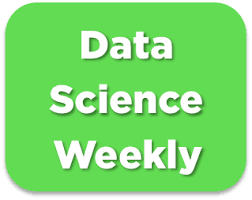

# Challenge : predict conversions 🏆🏆

**Contexte.** Le site *datascienceweekly.org* propose une newsletter hebdomadaire.
L'équipe souhaite savoir s'il est possible de **prédire si un visiteur va
s'inscrire** à partir de quelques informations simples, et surtout
**identifier des leviers d'action** pour améliorer le taux de conversion.

**Données.** `conversion_data_train.csv` (avec la cible `converted`) et
`conversion_data_test.csv` (sans cible, utilisé pour la soumission).

**Métrique du challenge : le F1-score**, calculé sur la classe « conversion ».
La classe est très minoritaire (environ 3 %), donc l'accuracy n'est pas
informative. Le F1 est le critère principal de ce notebook ; PR-AUC et
ROC-AUC servent de compléments.

**Etapes du projet**
1. *Read file with labels* : chargement, contrôle qualité et nettoyage
2. *Explore dataset* : analyse exploratoire
3. *Make your model* : choix des variables et séparation train / test
4. *Training pipeline* : préparation, comparaison de modèles en validation croisée (sur le train uniquement), amélioration (seuil de décision, hyperparamètres), entraînement du modèle retenu
5. *Test pipeline* et *Performance assessment* : évaluation finale **unique** sur le jeu de test, suivi MLflow
6. *Train best classifier on all data* : ré-entraînement sur toutes les données étiquetées, prédictions sur `conversion_data_test.csv` et export
7. *Analyzing the coefficients* : interprétation du modèle et recommandations


# Import libraries

In [1]:
import pandas as pd
import numpy as np
from copy import deepcopy
from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    classification_report,
    f1_score,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)

from xgboost import XGBClassifier

import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

import mlflow

# setting Jedha color palette as default
pio.templates["jedha"] = go.layout.Template(
    layout_colorway=["#4B9AC7", "#4BE8E0", "#9DD4F3", "#97FBF6", "#2A7FAF", "#23B1AB", "#0E3449", "#015955"]
)
pio.templates.default = "jedha"
pio.renderers.default = "svg" # to be replaced by "iframe" if working on JULIE
from IPython.display import display

## Configuration

In [2]:
SEED = 42
# Suffix of the submission file:
# conversion_data_test_predictions_[name].csv
SUBMISSION_NAME = "qs"

# The notebook is in notebooks/, the data in data/ at the project root
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DATA_DIR = ROOT / "data"
IMG_DIR = ROOT / "assets" / "images"
SUBMISSION_DIR = ROOT / "submissions"
MLFLOW_DIR = ROOT / "mlruns"
for folder in (IMG_DIR, SUBMISSION_DIR, MLFLOW_DIR):
    folder.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    """Save the current figure in assets/images (reused in the slides)."""
    plt.savefig(IMG_DIR / name, dpi=150, bbox_inches="tight")

# Read file with labels

In [3]:
data = pd.read_csv(DATA_DIR / 'conversion_data_train.csv')
print('Set with labels (our train+test) :', data.shape)

Set with labels (our train+test) : (284580, 6)


In [4]:
data.head()

,country,age,new_user,source,total_pages_visited,converted
0,China,22,1,Direct,2,0
1,UK,21,1,Ads,3,0
2,Germany,20,0,Seo,14,1
3,US,23,1,Seo,3,0
4,US,28,1,Direct,3,0


## Data quality

In [5]:
quality = pd.DataFrame({
    "dtype": data.dtypes,
    "missing": data.isna().sum(),
    "unique": data.nunique(),
})
display(quality)

nb_dup = data.duplicated().sum()
print(f"Lignes strictement identiques : {nb_dup:,} "
      f"({nb_dup / len(data):.1%})")
display(data.describe().round(2))

,dtype,missing,unique
country,str,0,4
age,int64,0,60
new_user,int64,0,2
source,str,0,3
total_pages_visited,int64,0,29
converted,int64,0,2


Lignes strictement identiques : 268,769 (94.4%)


,age,new_user,total_pages_visited,converted
count,284580.00,284580.00,284580.00,284580.00
mean,30.56,0.69,4.87,0.03
std,8.27,0.46,3.34,0.18
min,17.00,0.00,1.00,0.00
25%,24.00,0.00,2.00,0.00
50%,30.00,1.00,4.00,0.00
75%,36.00,1.00,7.00,0.00
max,123.00,1.00,29.00,1.00


**Interprétation**
- Aucune valeur manquante.
- Les lignes dupliquées sont très nombreuses. Ce n'est **pas une anomalie** :
  il n'y a que cinq variables, donc des visiteurs différents
  peuvent avoir le même profil. Nous les conservons, car les supprimer
  fausserait le taux de conversion.
- L'âge maximum est de 123 ans, ce qui est potentiellement un outlier. Nous l'examinons
  ci-dessous.

### Outliers

In [6]:
display(data[data["age"] > 90])
print("Troisième âge le plus élevé :",
      data["age"].nlargest(3).iloc[-1])

,country,age,new_user,source,total_pages_visited,converted
11331,UK,111,0,Ads,10,1
233196,Germany,123,0,Seo,15,1


Troisième âge le plus élevé : 79


Seules **2 lignes** dépassent 90 ans (123 et 111 ans). Ce sont de potentielles valeurs aberrantes.  
Ces deux lignes seront supprimées pour la suite. (2 lignes sur 284 580 : impact négligeable).

In [7]:
data = data[data["age"] <= 90].reset_index(drop=True)
print(f"Train après nettoyage : {len(data):,} lignes")

Train après nettoyage : 284,578 lignes


# Explore dataset

In [8]:
# The dataset is quite big : you must create a sample of the dataset before making any visualizations !
# The sample is used for the distributions only: conversion rates are computed on all the rows
data_sample = data.sample(10000, random_state=SEED)

target_variable = 'converted'
categorical_columns = ['country', 'source']
overall_rate = data[target_variable].mean()

## Target variable

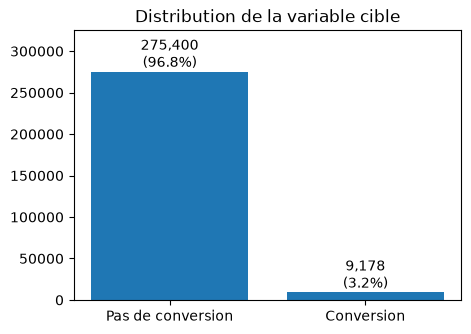

In [9]:
counts = data[target_variable].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(5, 3.5))

bars = ax.bar(["Pas de conversion", "Conversion"], counts)

for bar, value in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, value,
            f"{value:,}\n({value / counts.sum():.1%})",
            ha="center", va="bottom")

ax.set_ylim(0, counts.max() * 1.18)

ax.set_title("Distribution de la variable cible")

ax.grid(False)

save_fig("01_target_variable.png")

plt.show()

La classe « conversion » représente environ **3,2 %** des visiteurs. Un modèle
qui prédirait toujours « pas de conversion » aurait 96,8 % d'accuracy mais un
F1 nul. D'où le choix du F1 comme métrique principale.

## Explanatory variables

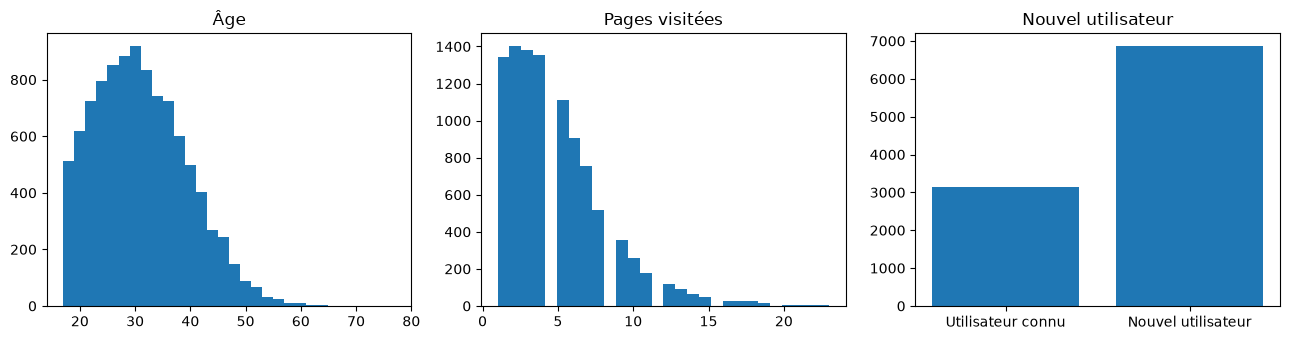

country (% du trafic) : {'US': 56.3, 'China': 24.3, 'UK': 15.3, 'Germany': 4.1}
source (% du trafic) : {'Seo': 49.0, 'Ads': 28.1, 'Direct': 22.9}


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

axes[0].hist(data_sample["age"], bins=30)
axes[0].set_title("Âge")

axes[1].hist(data_sample["total_pages_visited"], bins=28)
axes[1].set_title("Pages visitées")

new_counts = data_sample["new_user"].value_counts().sort_index()

axes[2].bar(["Utilisateur connu", "Nouvel utilisateur"], new_counts)
axes[2].set_title("Nouvel utilisateur")

plt.tight_layout()
save_fig("02_distributions.png")
plt.show()

for col in categorical_columns:
    share = data[col].value_counts(normalize=True).mul(100).round(1)
    print(f"{col} (% du trafic) :", share.to_dict())

## Relation avec la conversion

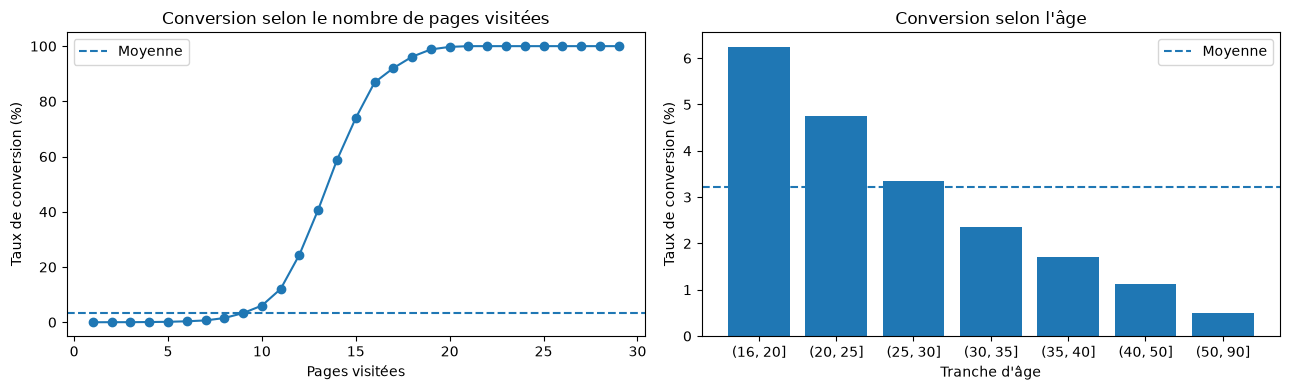

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

by_pages = data.groupby("total_pages_visited")[target_variable].mean().mul(100)

axes[0].plot(by_pages.index, by_pages.values, marker="o")
axes[0].axhline(overall_rate * 100, ls="--", label="Moyenne")
axes[0].set_xlabel("Pages visitées")
axes[0].set_ylabel("Taux de conversion (%)")
axes[0].set_title("Conversion selon le nombre de pages visitées")
axes[0].legend()

age_bins = pd.cut(data["age"], [16, 20, 25, 30, 35, 40, 50, 90])
by_age = data.groupby(age_bins, observed=True)[target_variable].mean().mul(100)

axes[1].bar(by_age.index.astype(str), by_age.values)
axes[1].axhline(overall_rate * 100, ls="--", label="Moyenne")
axes[1].set_xlabel("Tranche d'âge")
axes[1].set_ylabel("Taux de conversion (%)")
axes[1].set_title("Conversion selon l'âge")
axes[1].legend()

plt.tight_layout()

save_fig("03_rate_pages_age.png")

plt.show()

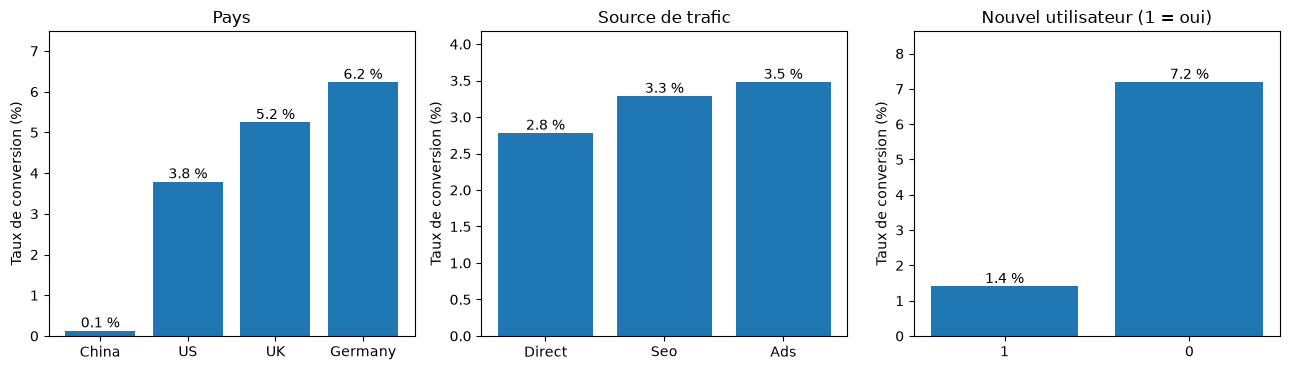

,traffic_share,conversion_rate,mean_pages
country,,,
China,24.29,0.13,4.55
US,56.27,3.79,4.93
UK,15.33,5.25,5.08
Germany,4.11,6.24,5.21


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

groups = [("country", "Pays"), ("source", "Source de trafic"),
          ("new_user", "Nouvel utilisateur (1 = oui)")]

for ax, (col, title) in zip(axes, groups):
    rate = data.groupby(col)[target_variable].mean().mul(100).sort_values()
    bars = ax.bar(rate.index.astype(str), rate.values)
    for bar, value in zip(bars, rate.values):
        ax.text(bar.get_x() + bar.get_width() / 2, value,
                f"{value:.1f} %", ha="center", va="bottom")
    ax.set_ylim(0, rate.max() * 1.2)
    ax.set_title(title)
    ax.set_ylabel("Taux de conversion (%)")
    ax.grid(False)

plt.tight_layout()

save_fig("04_rate_categories.png")

plt.show()

summary = data.groupby("country").agg(
    traffic_share=(target_variable, lambda s: len(s) / len(data) * 100),
    conversion_rate=(target_variable, lambda s: s.mean() * 100),
    mean_pages=("total_pages_visited", "mean"),
).round(2)

display(summary.sort_values("conversion_rate"))

**Ce que montrent ces graphiques**
- **Pages visitées** : semble être le signal le plus fort. La
  relation n'est pas linéaire : le taux reste inférieur à 1 % jusqu'à 7 pages,
  atteint environ 6 % à 10 pages, 59 % à 14 pages, et **100 % à partir de
  21 pages**. Un tel comportement quasi déterministe est suspect : nous y
  revenons dans les recommandations.
- **Âge** : plus le visiteur est jeune, plus il convertit.
- **Nouvel utilisateur** : les visiteurs déjà connus convertissent nettement
  plus que les nouveaux.
- **Pays** : la Chine pèse environ un quart du trafic mais ne convertit
  quasiment pas. L'Allemagne, le Royaume-Uni et les États-Unis sont bien
  au-dessus.
- **Source** : l'écart entre `Ads`, `Seo` et `Direct` est faible.

Il s'agit d'observations sur les données à ce stade.

# Make your model

## Choose variables to use in the model, and create train and test sets
**Nous utilisons ici les cinq variables disponibles : l'EDA montre que `total_pages_visited` domine, mais l'âge, le statut de nouvel utilisateur et le pays peuvent porter aussi du signal. La source de trafic est conservée malgré les observations ci-dessus.**

`new_user` est binaire (0/1) : elle est traitée avec les variables numériques.

In [13]:
features_list = ['age', 'new_user', 'total_pages_visited', 'country', 'source']
numeric_indices = [0, 1, 2]
categorical_indices = [3, 4]
target_variable = 'converted'

In [14]:
X = data.loc[:, features_list]
Y = data.loc[:, target_variable]

print('Explanatory variables : ', X.columns)
print()

Explanatory variables :  Index(['age', 'new_user', 'total_pages_visited', 'country', 'source'], dtype='str')



**Le jeu de test (20 %) est mis de côté** : il ne servira qu'**une seule fois**, à la toute fin. Tous les choix (modèle, hyperparamètres, seuil) sont faits en validation croisée sur le jeu d'entraînement. La séparation est stratifiée pour conserver la proportion de conversions dans les deux jeux.

In [15]:
# Divide dataset Train set & Test set 
print("Dividing into train and test sets...")
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, stratify=Y, random_state=SEED)
print("...Done.")
print(f"Train : {len(X_train):,} lignes | conversion {Y_train.mean():.2%}")
print(f"Test  : {len(X_test):,} lignes | conversion {Y_test.mean():.2%}")
print()

Dividing into train and test sets...
...Done.
Train : 227,662 lignes | conversion 3.22%
Test  : 56,916 lignes | conversion 3.23%



## Training pipeline

### Preprocessing

Les transformations sont regroupées dans un `ColumnTransformer` (`featureencoder`) : elles sont apprises uniquement sur les données d'entraînement (et, en validation croisée, sur celles de chaque pli : pas de fuite d'information).

- Variables numériques : imputation par la médiane, puis standardisation.
- Variables catégorielles : imputation par la modalité la plus fréquente, puis encodage *one-hot*. Les modalités de référence (`US` et `Seo`, les plus fréquentes) sont retirées, ce qui rend les coefficients de la régression logistique lisibles : ils se comparent à cette référence.

In [16]:
# Put here all the preprocessings
print("Defining the preprocessings...")

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop=['US', 'Seo'], handle_unknown='ignore', sparse_output=False))
])

featureencoder = ColumnTransformer(
    transformers=[
        ('numeric', numeric_transformer, numeric_indices),
        ('categorical', categorical_transformer, categorical_indices)
    ]
)


def make_pipeline(classifier, prep=featureencoder):
    """Preprocessing + classifier in a single estimator (used for cross-validation)."""
    return Pipeline([("preprocessor", prep), ("model", classifier)])

print("...Done.")

Defining the preprocessings...
...Done.


### Cadre d'évaluation

**Validation croisée.** Chaque modèle est évalué par une validation croisée
stratifiée à 5 plis sur le jeu d'entraînement. On obtient pour chaque ligne
une probabilité prédite par un modèle qui **ne l'a pas vue** (prédictions
« out-of-fold »).

**Pourquoi le seuil compte.** Un classifieur renvoie une probabilité. Par
défaut on prédit « conversion » au-dessus de 0,5, mais ce seuil n'est pas
forcément le meilleur pour le F1 quand la classe est rare. Pour chaque modèle
nous comparons donc :
- le **F1 au seuil 0,5** ;
- le **F1 au meilleur seuil** (celui qui maximise le F1 sur les prédictions
  out-of-fold) ;
- le PR-AUC et le ROC-AUC, qui ne dépendent pas du seuil.

In [17]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def oof_probabilities(model, X_data, y_data):
    """Out-of-fold probabilities of the positive class."""
    return cross_val_predict(
        model, X_data, y_data, cv=CV, method="predict_proba"
    )[:, 1]


def best_f1_threshold(y_true, proba):
    """Return the threshold that maximises F1, and the F1 reached."""
    precision, recall, thresholds = precision_recall_curve(y_true, proba)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    best = f1[:-1].argmax()
    return thresholds[best], f1[best]


def summarize(y_true, proba):
    """Ligne du tableau comparatif."""
    threshold, best_f1 = best_f1_threshold(y_true, proba)
    return pd.Series({
        "f1_at_0.5": f1_score(y_true, proba >= 0.5),
        "f1_best_threshold": best_f1,
        "best_threshold": threshold,
        "pr_auc": average_precision_score(y_true, proba),
        "roc_auc": roc_auc_score(y_true, proba),
    })

### Comparaison de modèles de base

Trois familles de modèles, de complexité croissante, avec des réglages
standard :
- **Régression logistique** : simple et interprétable ;
- **Random Forest** : forêt d'arbres, capture les relations non linéaires ;
- **XGBoost** : *gradient boosting*, souvent très performant sur données
  tabulaires.

Nous ajoutons une régression logistique avec `class_weight="balanced"`
(qui donne plus de poids à la classe rare) pour voir son effet sur le F1.

In [18]:
baselines = {
    "Logistic Regression": make_pipeline(
        LogisticRegression(max_iter=1000)),
    "Logistic Regression (balanced)": make_pipeline(
        LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Random Forest": make_pipeline(
        RandomForestClassifier(n_estimators=100, min_samples_leaf=5,
                               n_jobs=-1, random_state=SEED)),
    "XGBoost": make_pipeline(
        XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=4,
                      n_jobs=-1, random_state=SEED)),
}

oof = {}
results = {}
for name, model in baselines.items():
    oof[name] = oof_probabilities(model, X_train, Y_train)
    results[name] = summarize(Y_train, oof[name])

results_df = pd.DataFrame(results).T
display(results_df.round(4))

,f1_at_0.5,f1_best_threshold,best_threshold,pr_auc,roc_auc
Logistic Regression,0.7635,0.7718,0.4283,0.8452,0.9859
Logistic Regression (balanced),0.5112,0.7719,0.9509,0.8451,0.9859
Random Forest,0.7542,0.7623,0.3716,0.8227,0.9733
XGBoost,0.7612,0.7702,0.3565,0.8423,0.9856


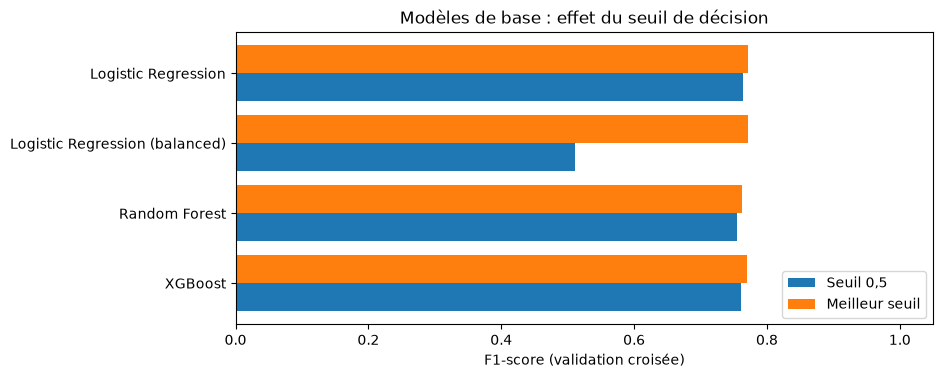

In [19]:
fig, ax = plt.subplots(figsize=(9, 3.8))
pos = np.arange(len(results_df))
ax.barh(pos + 0.2, results_df["f1_at_0.5"], height=0.4,
        label="Seuil 0,5")
ax.barh(pos - 0.2, results_df["f1_best_threshold"], height=0.4,
        label="Meilleur seuil")
ax.set_yticks(pos)
ax.set_yticklabels(results_df.index)
ax.invert_yaxis()
ax.set_xlabel("F1-score (validation croisée)")
ax.set_title("Modèles de base : effet du seuil de décision")
ax.set_xlim(0, 1.05)
ax.legend(loc="lower right")
save_fig("05_baselines.png")
plt.show()

**Lecture.**
- Une fois le seuil réglé, les modèles sont à un niveau très proche : **la
  complexité n'apporte presque rien ici**. Les variables sont peu nombreuses
  et le signal est surtout porté par `total_pages_visited`.
- Le **seuil de décision** est impactant uniquement dans le cas de la régression logistique balanced.
- `class_weight="balanced"` **dégrade fortement le F1 au seuil 0,5** : le
  modèle prédit trop de conversions et la précision s'effondre. Avec le seuil
  optimisé il retrouve le niveau de la régression logistique classique : il ne
  fait que déplacer le seuil. Pour optimiser le F1, mieux vaut un modèle non
  pondéré dont on règle le seuil directement.

### Amélioration du modèle

#### Réglage du seuil de décision

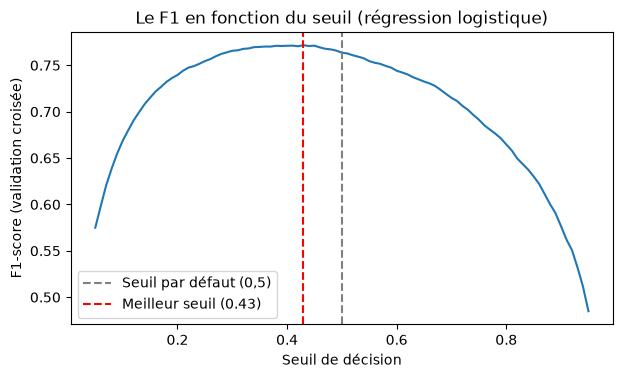

F1 à 0,5 : 0.7635 | F1 au seuil 0.43 : 0.7718


In [20]:
proba_lr = oof["Logistic Regression"]
grid_thresholds = np.linspace(0.05, 0.95, 91)
f1_curve = [f1_score(Y_train, proba_lr >= t) for t in grid_thresholds]
best_t, best_f1 = best_f1_threshold(Y_train, proba_lr)

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(grid_thresholds, f1_curve)
ax.axvline(0.5, color="grey", ls="--", label="Seuil par défaut (0,5)")
ax.axvline(best_t, color="red", ls="--",
           label=f"Meilleur seuil ({best_t:.2f})")
ax.set_xlabel("Seuil de décision")
ax.set_ylabel("F1-score (validation croisée)")
ax.set_title("Le F1 en fonction du seuil (régression logistique)")
ax.legend()
save_fig("06_threshold.png")
plt.show()
print(f"F1 à 0,5 : {f1_score(Y_train, proba_lr >= 0.5):.4f} | "
      f"F1 au seuil {best_t:.2f} : {best_f1:.4f}")

Abaisser le seuil (environ 0,43 au lieu de 0,5) permet de **capter plus de
vraies conversions** au prix d'un peu de précision. Le gain de F1 est réel
mais **modeste** (moins d'un point), et il est obtenu sans modèle plus complexe.

#### Réglage léger des hyperparamètres

Nous utilisons `GridSearchCV` sur des grilles volontairement petites. Le
critère de sélection est le **PR-AUC**, qui juge la qualité du classement des
probabilités sans dépendre du seuil. Le seuil est ensuite optimisé pour le F1
sur les prédictions out-of-fold du meilleur modèle.

In [21]:
param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.1, 1, 10]},
    "XGBoost": {"model__max_depth": [2, 3, 4],
                "model__n_estimators": [100, 200]},
}

tuned_models = {}
tuned_params = {}
for name, grid in param_grids.items():
    search = GridSearchCV(
        baselines[name], grid, scoring="average_precision", cv=CV,
        n_jobs=-1,
    )
    search.fit(X_train, Y_train)
    tuned_name = f"{name} (tuned)"
    tuned_models[tuned_name] = search.best_estimator_
    tuned_params[name] = search.best_params_
    print(f"{name} : {search.best_params_} "
          f"(PR-AUC CV = {search.best_score_:.4f})")

    oof[tuned_name] = oof_probabilities(search.best_estimator_, X_train,
                                        Y_train)
    results_df.loc[tuned_name] = summarize(Y_train, oof[tuned_name])

Logistic Regression : {'model__C': 1} (PR-AUC CV = 0.8452)
XGBoost : {'model__max_depth': 2, 'model__n_estimators': 200} (PR-AUC CV = 0.8436)


In [22]:
results_df.loc[name] = summarize(Y_train, oof[name])

display(results_df.round(4).sort_values("f1_best_threshold",
                                        ascending=False))

,f1_at_0.5,f1_best_threshold,best_threshold,pr_auc,roc_auc
Logistic Regression (balanced),0.5112,0.7719,0.9509,0.8451,0.9859
Logistic Regression,0.7635,0.7718,0.4283,0.8452,0.9859
Logistic Regression (tuned),0.7635,0.7718,0.4283,0.8452,0.9859
XGBoost (tuned),0.7635,0.7704,0.4410,0.8436,0.9858
XGBoost,0.7612,0.7702,0.3565,0.8423,0.9856
Random Forest,0.7542,0.7623,0.3716,0.8227,0.9733


**Lecture.**
- Le réglage des hyperparamètres ne change rien pour la régression logistique :
  la valeur par défaut (`C=1`) est déjà la meilleure de la grille, d'où des
  résultats identiques au modèle de base. XGBoost réglé gagne environ
  0,0002 de F1.
- Tous les modèles réglés se situent entre **0,770 et 0,772** de F1 qui semble être le plafond
avec les 5 variables disponibles.

**Choix du modèle final : la régression logistique** (`C=1`, seuil optimisé).
À performance équivalente, c'est le modèle le plus simple et le plus
interprétable, ce qui répond à la demande de l'équipe : comprendre les leviers
de la conversion.

### Train the final model

Le modèle retenu (régression logistique, `C` choisi par `GridSearchCV`, seuil optimisé en validation croisée) est maintenant entraîné sur **tout** le jeu d'entraînement, avec les mêmes étapes que le template : `fit_transform` sur le train, puis `transform` sur le test.

In [23]:
FINAL_NAME = "Logistic Regression (tuned)"
best_C = tuned_params["Logistic Regression"]["model__C"]
threshold = results_df.loc[FINAL_NAME, "best_threshold"]
print(f"Modèle retenu : {FINAL_NAME}")
print(f"Hyperparamètre C : {best_C}")
print(f"Seuil de décision (choisi en validation croisée) : {threshold:.3f}")

Modèle retenu : Logistic Regression (tuned)
Hyperparamètre C : 1
Seuil de décision (choisi en validation croisée) : 0.428


In [24]:
# Put here all the preprocessings
print("Encoding categorical features and standardizing numerical features...")

X_train = featureencoder.fit_transform(X_train)
print("...Done")
print(X_train[0:5,:])

Encoding categorical features and standardizing numerical features...
...Done
[[ 0.77869487  0.67629326 -0.56105227  0.          0.          1.
   1.          0.        ]
 [-0.43027253 -1.47864847  2.43067457  0.          0.          1.
   0.          0.        ]
 [-0.55116927 -1.47864847 -0.26187958  0.          0.          0.
   0.          1.        ]
 [-0.79296275 -1.47864847 -1.15939764  0.          0.          0.
   0.          0.        ]
 [ 0.29510791 -1.47864847 -0.86022495  0.          1.          0.
   1.          0.        ]]


In [25]:
# Train model
print("Train model...")
classifier = LogisticRegression(C=best_C, max_iter=1000) # C chosen by GridSearchCV
classifier.fit(X_train, Y_train)
print("...Done.")

Train model...
...Done.


In [26]:
# Predictions on training set (decision threshold chosen in cross-validation)
print("Predictions on training set...")
Y_train_proba = classifier.predict_proba(X_train)[:, 1]
Y_train_pred = (Y_train_proba >= threshold).astype(int)
print("...Done.")
print(Y_train_pred)
print()

Predictions on training set...
...Done.
[0 1 0 ... 0 0 0]



## Test pipeline

In [27]:
# Use X_test, and the same preprocessings as in training pipeline, 
# but call "transform()" instead of "fit_transform" methods (see example below)

print("Encoding categorical features and standardizing numerical features...")

X_test = featureencoder.transform(X_test)
print("...Done")
print(X_test[0:5,:])

Encoding categorical features and standardizing numerical features...
...Done
[[ 0.77869487  0.67629326 -0.86022495  1.          0.          0.
   0.          1.        ]
 [ 1.62497205  0.67629326 -0.56105227  1.          0.          0.
   1.          0.        ]
 [-0.79296275 -1.47864847  3.32819262  0.          0.          1.
   0.          1.        ]
 [ 0.41600465  0.67629326 -0.56105227  0.          0.          1.
   1.          0.        ]
 [-0.79296275  0.67629326  0.0372931   0.          0.          0.
   1.          0.        ]]


In [28]:
# Predictions on test set
# First and only use of the test set
print("Predictions on test set...")
Y_test_proba = classifier.predict_proba(X_test)[:, 1]
Y_test_pred = (Y_test_proba >= threshold).astype(int)
print("...Done.")
print(Y_test_pred)
print()

Predictions on test set...
...Done.
[0 0 1 ... 0 0 0]



## Performance assessment

In [29]:
# WARNING : Use the same score as the one that will be used by Kaggle !
# Here, the f1-score will be used to assess the performances on the leaderboard
print("f1-score on train set : ", f1_score(Y_train, Y_train_pred))
print("f1-score on test set : ", f1_score(Y_test, Y_test_pred))

f1-score on train set :  0.7709238343469447
f1-score on test set :  0.7635511280398476


In [30]:
# You can also check more performance metrics to better understand what your model is doing
print("Confusion matrix on train set : ")
print(confusion_matrix(Y_train, Y_train_pred))
print()
print("Confusion matrix on test set : ")
print(confusion_matrix(Y_test, Y_test_pred))
print()

Confusion matrix on train set : 
[[219174   1146]
 [  2018   5324]]

Confusion matrix on test set : 
[[54806   274]
 [  533  1303]]



In [31]:
test_metrics = {
    "f1": f1_score(Y_test, Y_test_pred),
    "precision": precision_score(Y_test, Y_test_pred),
    "recall": recall_score(Y_test, Y_test_pred),
    "pr_auc": average_precision_score(Y_test, Y_test_proba),
    "roc_auc": roc_auc_score(Y_test, Y_test_proba),
}
f1_default = f1_score(Y_test, Y_test_proba >= 0.5)

display(pd.Series(test_metrics, name="Test").round(4).to_frame())
print(f"Pour comparaison, F1 au seuil par défaut 0,5 : {f1_default:.4f}")
print()
print(classification_report(Y_test, Y_test_pred,
                            target_names=["Pas de conversion", "Conversion"],
                            digits=3))

,Test
f1,0.7636
precision,0.8263
recall,0.7097
pr_auc,0.8391
roc_auc,0.9859


Pour comparaison, F1 au seuil par défaut 0,5 : 0.7608

                   precision    recall  f1-score   support

Pas de conversion      0.990     0.995     0.993     55080
       Conversion      0.826     0.710     0.764      1836

         accuracy                          0.986     56916
        macro avg      0.908     0.852     0.878     56916
     weighted avg      0.985     0.986     0.985     56916



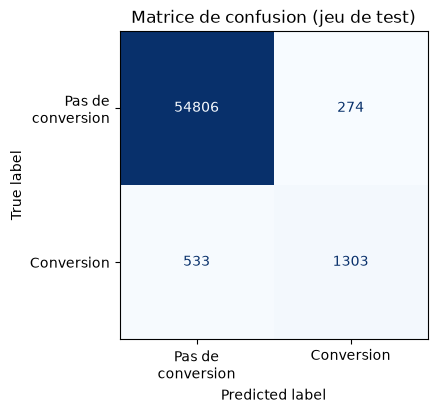

In [32]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    Y_test, Y_test_pred, display_labels=["Pas de\nconversion", "Conversion"],
    cmap="Blues", values_format="d", colorbar=False, ax=ax,
)
ax.set_title("Matrice de confusion (jeu de test)")
ax.grid(False)
save_fig("07_confusion_matrix.png")
plt.show()

**Lecture.**
- Le **F1 sur le jeu de test est de 0,764** (précision 0,83, rappel 0,71),
  contre 0,772 en validation croisée. L'écart d'environ 0,01 est du même ordre
  que l'incertitude d'un jeu de test contenant 1 836 conversions : pas de
  surapprentissage visible, le modèle généralise.
- Sur le test, le réglage du seuil apporte un gain très faible (0,7636 contre
  0,7608 au seuil 0,5). L'effet est cohérent avec la validation croisée mais
  il ne faut pas le surévaluer.
- Le modèle manque environ 29 % des conversions (rappel) et environ 17 % de
  ses alertes sont de fausses alertes (1 - précision). Le plafond de F1
  observé plus haut montre que certaines conversions ne s'expliquent pas par
  les variables disponibles.

## Experiment tracking with MLflow

Les résultats de tous les modèles testés sont enregistrés dans MLflow
(base locale dans `mlruns/`) pour garder une trace comparable des
expériences. Pour consulter l'interface, depuis la racine du projet :
`mlflow ui --backend-store-uri sqlite:///mlruns/mlflow.db`.

In [33]:
EXPERIMENT = "conversion_rate"
mlflow.set_tracking_uri(f"sqlite:///{(MLFLOW_DIR / 'mlflow.db').as_posix()}")
if mlflow.get_experiment_by_name(EXPERIMENT) is None:
    mlflow.create_experiment(
        EXPERIMENT,
        artifact_location=(MLFLOW_DIR / "artifacts").as_uri(),
    )
mlflow.set_experiment(EXPERIMENT)

# One run per candidate model (cross-validation metrics)
for name, row in results_df.iterrows():
    with mlflow.start_run(run_name=name):
        mlflow.set_tag("stage", "cross_validation")
        mlflow.log_metrics({f"cv_{k}": float(v) for k, v in row.items()})

# One run for the final model (test metrics)
with mlflow.start_run(run_name=f"{FINAL_NAME} - final"):
    mlflow.set_tag("stage", "final_test")
    mlflow.log_params({
        "C": best_C,
        "threshold": round(float(threshold), 4),
        "features": ",".join(features_list),
    })
    mlflow.log_metrics({f"test_{k}": v for k, v in test_metrics.items()})
print("Expériences enregistrées dans", MLFLOW_DIR)

2026/11/04 10:04:56 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/04 10:04:56 INFO mlflow.store.db.utils: Updating database tables


Expériences enregistrées dans c:\Users\DeatHunter\Desktop\CDSD_final\Bloc_3_Analyse_prédictive_de_données_structurées_par_l_intelligence_artificielle\cdsd_bloc3_projet_conversion_rate\mlruns


# Train best classifier on all data and use it to make predictions on X_without_labels
**Before making predictions on the file conversion_data_test.csv, let's train our model on ALL the data that was in conversion_data_train.csv. Sometimes, this allows to make tiny improvements in the score because we're using more examples to train the model.**

In [34]:
# Keep a copy of the model trained on the train set only: it is the one used
# for the interpretation below (the test set has not been used to fit it)
classifier_eval = deepcopy(classifier)

# Concatenate our train and test set to train your best classifier on all data with labels
X = np.append(X_train, X_test, axis=0)
Y = np.append(Y_train, Y_test)

classifier.fit(X, Y)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [35]:
# Read data without labels
data_without_labels = pd.read_csv(DATA_DIR / 'conversion_data_test.csv')
print('Prediction set (without labels) :', data_without_labels.shape)

# Warning : check consistency of features_list (must be the same than the features 
# used by your best classifier)
X_without_labels = data_without_labels.loc[:, features_list]

# The encoder was fitted on a DataFrame (selection of columns by position):
# we keep a DataFrame here, in the same column order as features_list
X_without_labels.head()

Prediction set (without labels) : (31620, 5)


,age,new_user,total_pages_visited,country,source
0,28,0,16,UK,Seo
1,22,1,5,UK,Direct
2,32,1,1,China,Seo
3,32,1,6,US,Ads
4,25,0,3,China,Seo


In [36]:
# WARNING : PUT HERE THE SAME PREPROCESSING AS FOR YOUR TEST SET
# CHECK YOU ARE USING X_without_labels
print("Encoding categorical features and standardizing numerical features...")

X_without_labels = featureencoder.transform(X_without_labels)
print("...Done")
print(X_without_labels[0:5,:])

Encoding categorical features and standardizing numerical features...
...Done
[[-0.30937579 -1.47864847  3.32819262  0.          0.          1.
   0.          0.        ]
 [-1.03475623  0.67629326  0.0372931   0.          0.          1.
   0.          1.        ]
 [ 0.17421117  0.67629326 -1.15939764  1.          0.          0.
   0.          0.        ]
 [ 0.17421117  0.67629326  0.33646578  0.          0.          0.
   1.          0.        ]
 [-0.67206601 -1.47864847 -0.56105227  1.          0.          0.
   0.          0.        ]]


In [37]:
# Make predictions and dump to file
# WARNING : MAKE SURE THE FILE IS A CSV WITH ONE COLUMN NAMED 'converted' AND NO INDEX !
# WARNING : FILE NAME MUST HAVE FORMAT 'conversion_data_test_predictions_[name].csv'
# where [name] is the name of your team/model separated by a '-'
# For example : [name] = AURELIE-model1
# (the decision threshold chosen in cross-validation is applied to the probabilities)
data = {
    'converted': (classifier.predict_proba(X_without_labels)[:, 1] >= threshold).astype(int)
}

Y_predictions = pd.DataFrame(columns=['converted'], data=data)

# Sanity checks before saving
assert len(Y_predictions) == len(data_without_labels)
assert list(Y_predictions.columns) == ['converted']
assert Y_predictions['converted'].isin([0, 1]).all()
print(f"Prédictions : {len(Y_predictions):,} lignes")
print(f"Taux de conversions prédites : {Y_predictions['converted'].mean():.2%} "
      f"(taux observé dans le train : {Y.mean():.2%})")

output_path = SUBMISSION_DIR / f'conversion_data_test_predictions_{SUBMISSION_NAME}.csv'
Y_predictions.to_csv(output_path, index=False)
print("Fichier enregistré :", output_path.name)

Prédictions : 31,620 lignes
Taux de conversions prédites : 2.82% (taux observé dans le train : 3.23%)
Fichier enregistré : conversion_data_test_predictions_qs.csv


## Analyzing the coefficients and interpreting the result

### Coefficients de la régression logistique

Chaque coefficient est converti en **odds ratio** (rapport de cotes) :
- un odds ratio **> 1** augmente les chances de conversion, **< 1** les
  diminue ;
- pour les variables numériques, il se lit « par unité » (une page de plus,
  un an de plus, nouvel utilisateur contre utilisateur connu) ;
- pour le pays et la source, il se lit **par rapport à la référence**
  (`US` et `Seo`) ;
- tout est calculé **toutes choses égales par ailleurs**.

In [38]:
# Model trained on the train set only (classifier_eval) and its fitted encoder
numeric_names = [features_list[i] for i in numeric_indices]
feature_names = [n.split("__")[1] for n in featureencoder.get_feature_names_out()]
scale = dict(zip(
    numeric_names,
    featureencoder.named_transformers_["numeric"].named_steps["scaler"].scale_,
))

coefs = pd.Series(classifier_eval.coef_[0], index=feature_names)
odds = {}
for feature, coef in coefs.items():
    # Numerical variables were standardised: go back to "per unit"
    if feature in scale:
        coef = coef / scale[feature]
    odds[feature] = np.exp(coef)
odds = pd.Series(odds).sort_values()

labels = {
    "total_pages_visited": "+1 page visitée",
    "age": "+1 an",
    "new_user": "Nouvel utilisateur (vs connu)",
    "country_China": "Chine (vs US)",
    "country_Germany": "Allemagne (vs US)",
    "country_UK": "Royaume-Uni (vs US)",
    "source_Ads": "Source Ads (vs Seo)",
    "source_Direct": "Source Direct (vs Seo)",
}
odds.index = [labels.get(i, i) for i in odds.index]
display(odds.round(3).to_frame("odds ratio"))

,odds ratio
Chine (vs US),0.046
Nouvel utilisateur (vs connu),0.177
Source Direct (vs Seo),0.812
+1 an,0.929
Source Ads (vs Seo),1.028
Royaume-Uni (vs US),1.388
Allemagne (vs US),1.773
+1 page visitée,2.132


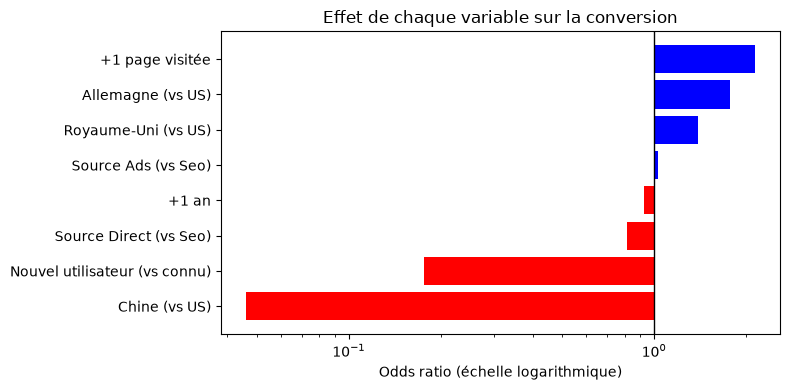

In [39]:
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["red" if v < 1 else "blue" for v in odds.values]
# Bars start at 1 (no effect) and go left (<1) or right (>1)
ax.barh(odds.index, odds.values - 1, left=1, color=colors)
ax.set_xscale("log")
ax.axvline(1, color="black", lw=1)
ax.set_xlabel("Odds ratio (échelle logarithmique)")
ax.set_title("Effet de chaque variable sur la conversion")
plt.tight_layout()
save_fig("08_odds_ratios.png")
plt.show()

### Recommandations

**Ce que disent les résultats**
- Toutes choses égales par ailleurs : un visiteur **chinois** a des chances de
  conversion environ 20 fois plus faibles qu'un visiteur américain (odds
  ratio 0,05), un **nouvel utilisateur** environ 5 à 6 fois plus faibles qu'un
  utilisateur connu (0,18), l'**Allemagne** et le **Royaume-Uni** sont
  au-dessus des États-Unis (1,77 et 1,39), et chaque année d'âge en plus
  réduit les chances d'environ 7 %.
- La **source de trafic** n'a un effet faible, avec Direct un peu en dessous.

**Leviers d'action proposés**
1. **Comprendre le cas de la Chine.** C'est un quart du trafic pour 0,13 % de
   conversion, alors que les visiteurs chinois consultent autant de pages que
   les autres (4,5 contre 4,9 en moyenne). Ils s'intéressent donc au contenu
   mais ne s'inscrivent pas : langue ou localisation de la page d'inscription,
   formulaire inaccessible depuis le pays, ou trafic non qualifié (robots).
   À titre d'ordre de grandeur, si la Chine convertissait comme les États-Unis,
   le site gagnerait environ 2 500 inscriptions, soit près de +28 % (hypothèse
   haute, non garantie).
2. **Transformer les nouveaux visiteurs.** Les visiteurs déjà connus
   convertissent environ cinq fois plus (7,2 % contre 1,4 %) : travailler
   l'appel à l'inscription dès la première visite, et encourager le retour sur le site.
3. **Développer l'acquisition en Allemagne et au Royaume-Uni.** Ces pays
   convertissent le mieux mais pèsent peu dans le trafic (4 % et 15 %).
4. **Cibler les publics plus jeunes** : les moins de 25 ans convertissent
   nettement plus que les plus de 40 ans.
5. **Ne pas arbitrer les canaux sur leur taux de conversion** : Les écarts sont modestes. Le choix doit se faire sur
   le coût d'acquisition.

**Précautions importantes**
- **`total_pages_visited` n'est pas un levier prouvé.** Au-delà de 15 pages
  le taux de conversion dépasse 74 %, et il atteint 100 % à partir de
  21 pages. Ce comportement quasi déterministe suggère que le nombre de pages
  peut être en partie une **conséquence** de l'inscription (par exemple si des
  pages visitées après l'inscription sont comptées) ou le reflet d'une
  intention déjà acquise. Il faut demander à l'équipe comment cette variable
  est mesurée. Si elle inclut des pages postérieures à l'inscription, le modèle
  ne pourrait pas servir à prédire une conversion *avant* qu'elle ait lieu.
  Pour tester un vrai levier (par exemple des liens de contenu associé), il
  faut une expérience contrôlée (test A/B), pas une lecture des corrélations.
- Les odds ratios décrivent des **associations**, pas des causes.

# Conclusion

**Bilan**
- Un modèle de régression logistique à cinq variables atteint un **F1 de
  0,764 sur le jeu de test** (0,772 en validation croisée), sans
  surapprentissage visible.
- Des modèles plus complexes (Random Forest, XGBoost), un réglage des
  hyperparamètres n'apportent peu : le plafond est d'environ 0,77 avec ces variables.
- Le **réglage du seuil de décision** est le seul levier simple qui améliore
  légèrement le F1, et `class_weight="balanced"` est à éviter quand on vise le
  F1 au seuil par défaut.
- Pistes métier : comprendre la très faible conversion en Chine, travailler la
  conversion des nouveaux visiteurs, et clarifier la mesure de
  `total_pages_visited`.

**Limites et pistes**
- Seulement cinq variables, dont une dominante dont la mesure est à
  clarifier : pour aller plus loin, il faudrait des données de comportement
  (pages vues, temps passé, page d'entrée, appareil).
- Les nombreux profils identiques limitent la capacité de tout modèle à
  distinguer des visiteurs qui ont les mêmes caractéristiques.
- Piste d'amélioration du protocole : valider la stabilité du score avec des
  répétitions de la validation croisée.